In [1]:
pip install -q torch torchvision datasets gradio scikit-learn pillow matplotlib

Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gtts 2.5.4 requires click<8.2,>=7.1, but you have click 8.5.1 which is incompatible.
python-lsp-server 1.13.1 requires jedi<0.20.0,>=0.17.2, but you have jedi 0.20.0 which is incompatible.
spyder 6.1.0 requires jedi<0.20.0,>=0.17.2, but you have jedi 0.20.0 which is incompatible.

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import random
from pathlib import Path
from collections import Counter

# Short cache directory avoids Windows MAX_PATH issues during file writes
os.environ["HF_HOME"] = r"C:\hf_cache"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
Path(r"C:\hf_cache").mkdir(parents=True, exist_ok=True)

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from huggingface_hub import snapshot_download
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report
import gradio as gr


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
outputs_dir = project_root / "outputs"
outputs_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = outputs_dir / "best_mars_resnet18.pt"

print("Project root:", project_root)
print("Checkpoint path:", checkpoint_path)

Using device: cpu
Project root: c:\Users\Hp\OneDrive\Desktop\project-2-mars
Checkpoint path: c:\Users\Hp\OneDrive\Desktop\project-2-mars\outputs\best_mars_resnet18.pt


In [3]:
import zipfile

DATASET_ID = "RAAArity/Mars_surface_image_Curiosity_rover_labeled_data_set_version_1"
local_repo_dir = Path(
    snapshot_download(
        repo_id=DATASET_ID,
        repo_type="dataset",
        local_dir=r"C:\hf_cache\mars_msl_v1",
    )
)
print("Dataset directory:", local_repo_dir)

# Extract any .zip archive if images are packed inside one
for zf in local_repo_dir.rglob("*.zip"):
    extract_target = zf.parent
    print("Extracting archive:", zf)
    with zipfile.ZipFile(zf, "r") as z:
        z.extractall(extract_target)

# Build a lookup map: lowercased filename -> full path (handles any subfolder structure)
img_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
filename_to_path = {}
for p in local_repo_dir.rglob("*"):
    if p.is_file() and p.suffix.lower() in img_exts:
        filename_to_path.setdefault(p.name.lower(), str(p))

print(f"Total image files indexed on disk: {len(filename_to_path)}")

# Parse class names from msl_synset_words-indexed.txt if present
synset_candidates = [
    local_repo_dir / "msl_synset_words-indexed.txt",
    local_repo_dir / "msl_synset_words.txt",
    local_repo_dir / "labels.txt",
]
parsed_names = []
for syn_file in synset_candidates:
    if syn_file.exists():
        for line in syn_file.read_text(encoding="utf-8", errors="ignore").splitlines():
            line = line.strip()
            if not line:
                continue
            parts = line.split(maxsplit=1)
            parsed_names.append(parts[1].strip() if len(parts) == 2 and parts[0].isdigit() else line)
        if parsed_names:
            break


def parse_split_file(txt_path: Path, root_dir: Path):
    items = []
    missing_examples = []
    if not txt_path.exists():
        print(f"Warning: split file not found -> {txt_path}")
        return items

    for line in txt_path.read_text(encoding="utf-8", errors="ignore").splitlines():
        line = line.strip()
        if not line:
            continue
        parts = line.rsplit(maxsplit=1)
        if len(parts) != 2:
            continue
        rel_path, raw_label = parts[0].strip(), parts[1].strip()
        if not raw_label.lstrip("-").isdigit():
            continue
        lbl_int = int(raw_label)

        candidate = root_dir / rel_path.lstrip("/\\")
        if candidate.is_file():
            items.append((str(candidate), lbl_int))
            continue

        fname = Path(rel_path.replace("\\", "/")).name.lower()
        if fname in filename_to_path:
            items.append((filename_to_path[fname], lbl_int))
        elif len(missing_examples) < 5:
            missing_examples.append(line)

    if not items and missing_examples:
        print(f"Sample unmatched lines in {txt_path.name}: {missing_examples}")
    return items


train_items = parse_split_file(local_repo_dir / "train-calibrated-shuffled.txt", local_repo_dir)
val_items = parse_split_file(local_repo_dir / "val-calibrated-shuffled.txt", local_repo_dir)
test_items = parse_split_file(local_repo_dir / "test-calibrated-shuffled.txt", local_repo_dir)

all_ids = [lbl for _, lbl in (train_items + val_items + test_items)]
max_id = max(all_ids) if all_ids else 0
num_classes = max(len(parsed_names), max_id + 1)

if len(parsed_names) >= num_classes:
    label_names = parsed_names[:num_classes]
else:
    label_names = [
        parsed_names[i] if i < len(parsed_names) else f"MSL_Class_{i}"
        for i in range(num_classes)
    ]

label_to_idx = {name: i for i, name in enumerate(label_names)}
idx_to_label = {i: name for i, name in enumerate(label_names)}

for split_name, split_list in [("train", train_items), ("validation", val_items), ("test", test_items)]:
    counts = Counter(idx_to_label[lbl] for _, lbl in split_list if 0 <= lbl < num_classes)
    print(f"\n=== {split_name} (samples={len(split_list)}) ===")
    for idx_c, cls_name in enumerate(label_names):
        print(f"  [{idx_c:02d}] {cls_name:<22}: {counts[cls_name]}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Dataset directory: C:\hf_cache\mars_msl_v1
Extracting archive: C:\hf_cache\mars_msl_v1\msl-images.zip
Total image files indexed on disk: 6737

=== train (samples=3746) ===
  [00] apxs                  : 30
  [01] apxs cal target       : 6
  [02] chemcam cal target    : 15
  [03] chemin inlet open     : 47
  [04] drill                 : 19
  [05] drill holes           : 36
  [06] drt front             : 4
  [07] drt side              : 8
  [08] ground                : 2343
  [09] horizon               : 224
  [10] inlet                 : 165
  [11] mahli                 : 14
  [12] mahli cal target      : 32
  [13] mastcam               : 36
  [14] mastcam cal target    : 101
  [15] observation tray      : 85
  [16] portion box           : 18
  [17] portion tube          : 73
  [18] portion tube opening  : 8
  [19] rems uv sensor        : 12
  [20] rover rear deck       : 57
  [21] scoop                 : 166
  [22] sun                   : 0
  [23] turret                : 178
  [24] whe

In [4]:
print([p.name for p in Path(r"C:\hf_cache\mars_msl_v1").iterdir()])

['.cache', '.gitattributes', 'calibrated', 'Importnat', 'msl-images.zip', 'msl_synset_words-indexed.txt', 'README.md', 'README.txt', 'test-calibrated-shuffled.txt', 'train-calibrated-shuffled.txt', 'val-calibrated-shuffled.txt']


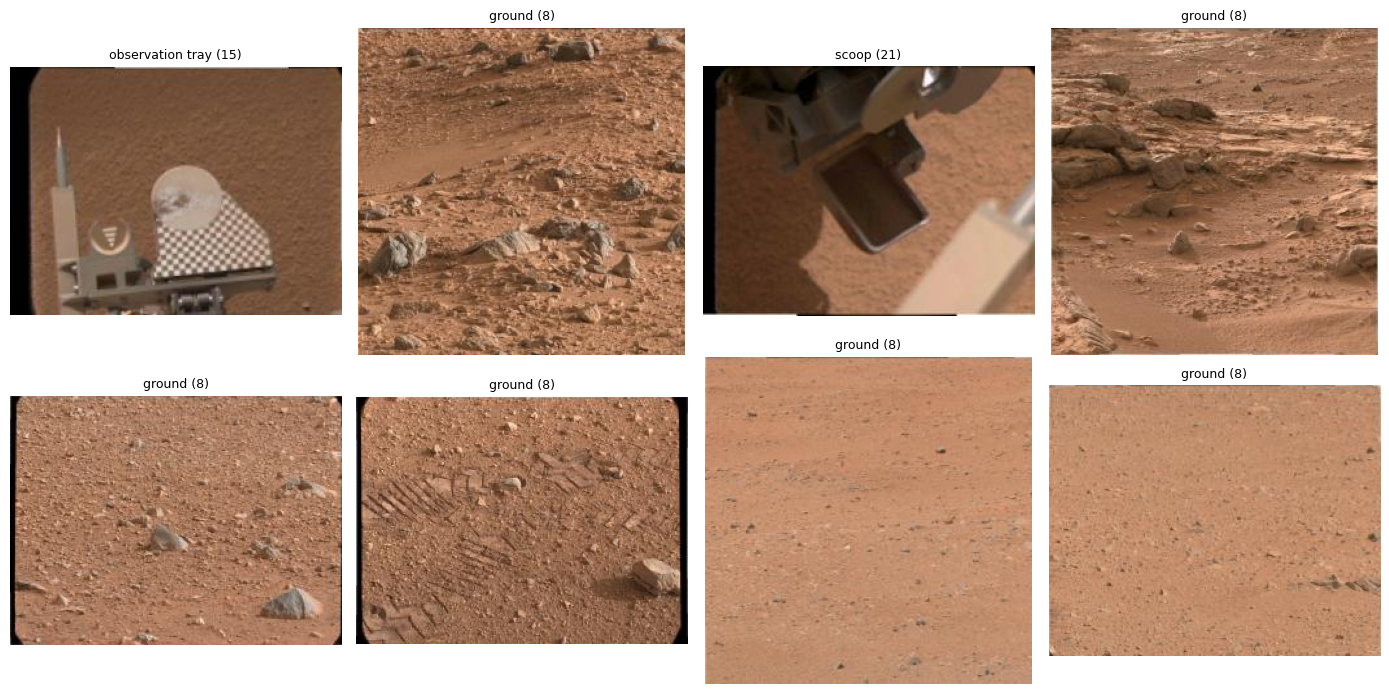

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax, (img_path, lbl_idx) in zip(axes, train_items[:8]):
    with Image.open(img_path) as im:
        rgb = im.convert("RGB").copy()
    ax.imshow(rgb)
    ax.set_title(f"{idx_to_label[lbl_idx]} ({lbl_idx})", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


class MarsCuriosityDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        with Image.open(img_path) as im:
            img = im.convert("RGB").copy()
        if self.transform:
            img = self.transform(img)
        return img, label


batch_size = 32
train_loader = DataLoader(
    MarsCuriosityDataset(train_items, transform=train_transform),
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)
val_loader = DataLoader(
    MarsCuriosityDataset(val_items, transform=eval_transform),
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)
test_loader = DataLoader(
    MarsCuriosityDataset(test_items, transform=eval_transform),
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print(f"Batches -> train: {len(train_loader)} | val: {len(val_loader)} | test: {len(test_loader)}")

Batches -> train: 118 | val: 52 | test: 41


In [7]:
def build_resnet18(num_classes: int, pretrained: bool = True) -> nn.Module:
    weights = models.ResNet18_Weights.DEFAULT if pretrained else None
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)


@torch.no_grad()
def evaluate_loader(model: nn.Module, loader: DataLoader, criterion: nn.Module):
    model.eval()
    total_loss = 0.0
    all_preds = []
    all_targets = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += loss.item() * images.size(0)
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

    avg_loss = total_loss / max(len(loader.dataset), 1)
    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    weighted_f1 = f1_score(all_targets, all_preds, average="weighted", zero_division=0)

    return {
        "loss": avg_loss,
        "acc": acc,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "targets": np.array(all_targets),
        "preds": np.array(all_preds),
    }


model = build_resnet18(num_classes=num_classes, pretrained=True)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

epochs = 10
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
best_val_macro_f1 = -1.0

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    scheduler.step()
    train_loss = running_loss / max(len(train_loader.dataset), 1)
    val_metrics = evaluate_loader(model, val_loader, criterion)

    print(
        f"Epoch {epoch:02d}/{epochs:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['acc']:.4f} | "
        f"Val Macro F1: {val_metrics['macro_f1']:.4f} | "
        f"Val Weighted F1: {val_metrics['weighted_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_val_macro_f1:
        best_val_macro_f1 = val_metrics["macro_f1"]
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "label_names": label_names,
                "num_classes": num_classes,
                "best_val_macro_f1": best_val_macro_f1,
                "epoch": epoch,
            },
            checkpoint_path,
        )
        print(f"  -> Saved best checkpoint to {checkpoint_path} (Val Macro F1: {best_val_macro_f1:.4f})")

Epoch 01/10 | Train Loss: 0.3643 | Val Loss: 1.1749 | Val Acc: 0.6244 | Val Macro F1: 0.4944 | Val Weighted F1: 0.6929
  -> Saved best checkpoint to c:\Users\Hp\OneDrive\Desktop\project-2-mars\outputs\best_mars_resnet18.pt (Val Macro F1: 0.4944)
Epoch 02/10 | Train Loss: 0.1273 | Val Loss: 1.4827 | Val Acc: 0.6720 | Val Macro F1: 0.6447 | Val Weighted F1: 0.6177
  -> Saved best checkpoint to c:\Users\Hp\OneDrive\Desktop\project-2-mars\outputs\best_mars_resnet18.pt (Val Macro F1: 0.6447)
Epoch 03/10 | Train Loss: 0.0634 | Val Loss: 1.0413 | Val Acc: 0.6835 | Val Macro F1: 0.6890 | Val Weighted F1: 0.6652
  -> Saved best checkpoint to c:\Users\Hp\OneDrive\Desktop\project-2-mars\outputs\best_mars_resnet18.pt (Val Macro F1: 0.6890)
Epoch 04/10 | Train Loss: 0.0461 | Val Loss: 0.7392 | Val Acc: 0.7665 | Val Macro F1: 0.5729 | Val Weighted F1: 0.7630
Epoch 05/10 | Train Loss: 0.0363 | Val Loss: 0.8777 | Val Acc: 0.7360 | Val Macro F1: 0.6548 | Val Weighted F1: 0.7106
Epoch 06/10 | Train Loss

In [8]:
ckpt = torch.load(checkpoint_path, map_location=device)
best_model = build_resnet18(num_classes=ckpt["num_classes"], pretrained=False)
best_model.load_state_dict(ckpt["model_state_dict"])
best_model.eval()

test_metrics = evaluate_loader(best_model, test_loader, criterion)
print(f"Checkpoint Epoch: {ckpt['epoch']} | Best Val Macro F1: {ckpt['best_val_macro_f1']:.4f}\n")
print(f"Test Accuracy    : {test_metrics['acc']:.4f}")
print(f"Test Macro F1    : {test_metrics['macro_f1']:.4f}")
print(f"Test Weighted F1 : {test_metrics['weighted_f1']:.4f}\n")

present_labels = sorted(set(test_metrics["targets"]).union(set(test_metrics["preds"])))
print(
    classification_report(
        test_metrics["targets"],
        test_metrics["preds"],
        labels=present_labels,
        target_names=[label_names[i] for i in present_labels],
        digits=4,
        zero_division=0,
    )
)

Checkpoint Epoch: 10 | Best Val Macro F1: 0.6996

Test Accuracy    : 0.7372
Test Macro F1    : 0.6395
Test Weighted F1 : 0.7432

                      precision    recall  f1-score   support

                apxs     1.0000    1.0000    1.0000        34
     apxs cal target     1.0000    1.0000    1.0000        14
  chemcam cal target     1.0000    0.9048    0.9500        21
   chemin inlet open     1.0000    0.9524    0.9756        84
               drill     0.3333    0.6500    0.4407        20
         drill holes     0.0000    0.0000    0.0000         0
           drt front     1.0000    0.3000    0.4615        60
            drt side     0.9630    0.1733    0.2938       150
              ground     0.9009    0.7874    0.8403       254
             horizon     0.5593    0.9167    0.6947        72
               inlet     0.0000    0.0000    0.0000        16
               mahli     0.4118    0.5833    0.4828        12
    mahli cal target     0.9787    0.8070    0.8846        57
  

In [9]:
@torch.no_grad()
def predict_mars_image(image):
    if image is None:
        return {}
    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.array(image))
    tensor = eval_transform(image.convert("RGB")).unsqueeze(0).to(device)
    logits = best_model(tensor)
    probs = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()

    top_k = min(5, len(label_names))
    top_idx = np.argsort(probs)[::-1][:top_k]
    return {label_names[i]: float(probs[i]) for i in top_idx}


example_dir = outputs_dir / "gradio_examples"
example_dir.mkdir(exist_ok=True)
example_paths = []
for i, (img_path, _) in enumerate(test_items[:4]):
    out_file = example_dir / f"test_sample_{i}.jpg"
    with Image.open(img_path) as im:
        im.convert("RGB").save(out_file)
    example_paths.append(str(out_file))

demo = gr.Interface(
    fn=predict_mars_image,
    inputs=gr.Image(type="pil", label="Upload Curiosity Rover Image"),
    outputs=gr.Label(num_top_classes=5, label="Top 5 Predicted Classes"),
    examples=example_paths if example_paths else None,
    title="Mars Curiosity Rover Image Classifier (ResNet-18)",
    description="Top-5 predictions across MSL Curiosity surface & rover component classes.",
)

demo.launch(share=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Sample #0 | True: drt side | Top-1: drill (54.43%)
   1. drill                  -> 0.5443
   2. drt side               -> 0.2224
   3. scoop                  -> 0.1841
   4. drt front              -> 0.0158
   5. portion box            -> 0.0118
Sample #1 | True: wheel | Top-1: wheel (100.00%)
   1. wheel                  -> 1.0000
   2. inlet                  -> 0.0000
   3. mahli cal target       -> 0.0000
   4. scoop                  -> 0.0000
   5. mahli                  -> 0.0000
Sample #2 | True: horizon | Top-1: horizon (99.98%)
   1. horizon                -> 0.9998
   2. mastcam                -> 0.0001
   3. ground                 -> 0.0000
   4. rover rear deck        -> 0.0000
   5. wheel                  -> 0.0000
Sample #3 | True: drt side | Top-1: wheel (46.36%)
   1. wheel                  -> 0.4636
   2. portion box            -> 0.2295
   3. scoop                  -> 0.1178
   4. drt side               -> 0.0883
   5. drill                  -> 0.0286


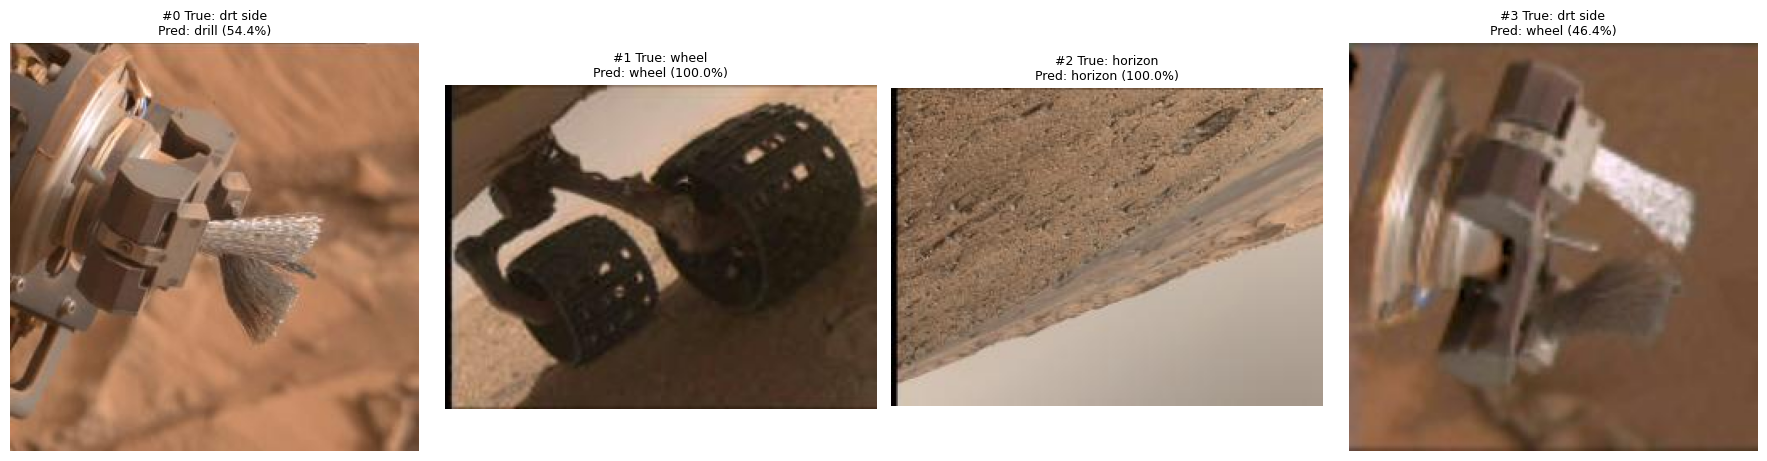

In [10]:
@torch.no_grad()
def run_final_model_test(ckpt_path: Path, samples: list, indices=(0, 1, 2, 3)):
    assert ckpt_path.exists(), f"Saved checkpoint not found at {ckpt_path}. Run Cell 6 first."

    saved = torch.load(ckpt_path, map_location=device)
    saved_classes = saved["label_names"]

    loaded_model = models.resnet18(weights=None)
    loaded_model.fc = nn.Linear(loaded_model.fc.in_features, saved["num_classes"])
    loaded_model.load_state_dict(saved["model_state_dict"])
    loaded_model.to(device)
    loaded_model.eval()

    valid_idx = [i for i in indices if 0 <= i < len(samples)]
    cols = max(len(valid_idx), 1)
    fig, axes = plt.subplots(1, cols, figsize=(4.5 * cols, 4.5))
    if cols == 1:
        axes = [axes]

    for ax, idx in zip(axes, valid_idx):
        img_path, true_idx = samples[idx]
        with Image.open(img_path) as im:
            rgb_img = im.convert("RGB").copy()

        x = eval_transform(rgb_img).unsqueeze(0).to(device)
        probs = torch.softmax(loaded_model(x), dim=1).squeeze(0).cpu().numpy()

        top_k = min(5, len(saved_classes))
        top_ids = np.argsort(probs)[::-1][:top_k]
        pred_1_label = saved_classes[top_ids[0]]
        pred_1_conf = probs[top_ids[0]]
        true_label = saved_classes[true_idx]

        print(f"Sample #{idx} | True: {true_label} | Top-1: {pred_1_label} ({pred_1_conf:.2%})")
        for rank, c_id in enumerate(top_ids, start=1):
            print(f"   {rank}. {saved_classes[c_id]:<22} -> {probs[c_id]:.4f}")

        ax.imshow(rgb_img)
        ax.set_title(f"#{idx} True: {true_label}\nPred: {pred_1_label} ({pred_1_conf:.1%})", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


run_final_model_test(checkpoint_path, test_items, indices=(0, 1, 2, 3))

Testing indices: [5, 2, 48, 77, 170]
Sample #5 | True: ground | Top-1: ground (99.80%)
   1. ground                 -> 0.9980
   2. horizon                -> 0.0013
   3. wheel                  -> 0.0001
   4. mastcam                -> 0.0001
   5. apxs                   -> 0.0001
Sample #2 | True: horizon | Top-1: horizon (99.98%)
   1. horizon                -> 0.9998
   2. mastcam                -> 0.0001
   3. ground                 -> 0.0000
   4. rover rear deck        -> 0.0000
   5. wheel                  -> 0.0000
Sample #48 | True: mastcam cal target | Top-1: rover rear deck (63.82%)
   1. rover rear deck        -> 0.6382
   2. ground                 -> 0.1766
   3. mastcam                -> 0.0405
   4. chemcam cal target     -> 0.0212
   5. horizon                -> 0.0172
Sample #77 | True: drill | Top-1: drill (99.99%)
   1. drill                  -> 0.9999
   2. drt front              -> 0.0000
   3. inlet                  -> 0.0000
   4. mahli                  -> 0.0000

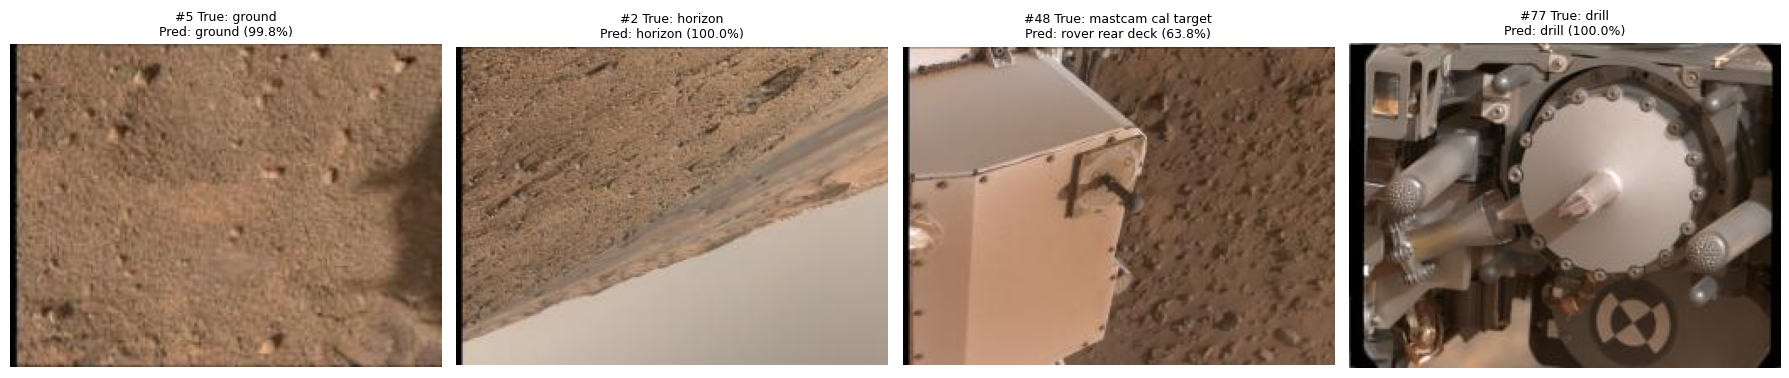

In [11]:
# Find the first test image index for several interesting classes and test them
target_check = ["ground", "horizon", "mastcam cal target", "drill", "portion tube"]
picked_indices = []
for cls_name in target_check:
    if cls_name in label_to_idx:
        target_id = label_to_idx[cls_name]
        match_idx = next((i for i, (_, lbl) in enumerate(test_items) if lbl == target_id), None)
        if match_idx is not None:
            picked_indices.append(match_idx)

print("Testing indices:", picked_indices)
run_final_model_test(checkpoint_path, test_items, indices=tuple(picked_indices[:4]))

In [13]:
@torch.no_grad()
def predict_any_image(image_path: str, ckpt_path: Path = checkpoint_path):
    saved = torch.load(ckpt_path, map_location=device)
    classes = saved["label_names"]

    net = models.resnet18(weights=None)
    net.fc = nn.Linear(net.fc.in_features, saved["num_classes"])
    net.load_state_dict(saved["model_state_dict"])
    net.to(device)
    net.eval()

    with Image.open(image_path) as im:
        rgb = im.convert("RGB").copy()

    tensor = eval_transform(rgb).unsqueeze(0).to(device)
    probs = torch.softmax(net(tensor), dim=1).squeeze(0).cpu().numpy()
    top_ids = np.argsort(probs)[::-1][: min(5, len(classes))]

    plt.figure(figsize=(4, 4))
    plt.imshow(rgb)
    plt.title(f"Top-1: {classes[top_ids[0]]} ({probs[top_ids[0]]:.1%})")
    plt.axis("off")
    plt.show()

    for rank, idx in enumerate(top_ids, start=1):
        print(f"{rank}. {classes[idx]:<22} : {probs[idx]:.4f}")

# Example: pass a path to any test/local image
# predict_any_image(test_items[0][0])

[ERR] #0 | True: drt side | Pred: drill (54.4%)
[OK] #1 | True: wheel | Pred: wheel (100.0%)
[OK] #2 | True: horizon | Pred: horizon (100.0%)
[ERR] #3 | True: drt side | Pred: wheel (46.4%)
[OK] #4 | True: mahli | Pred: mahli (100.0%)
[OK] #5 | True: ground | Pred: ground (99.8%)
[ERR] #6 | True: ground | Pred: horizon (68.0%)
[OK] #7 | True: ground | Pred: ground (100.0%)


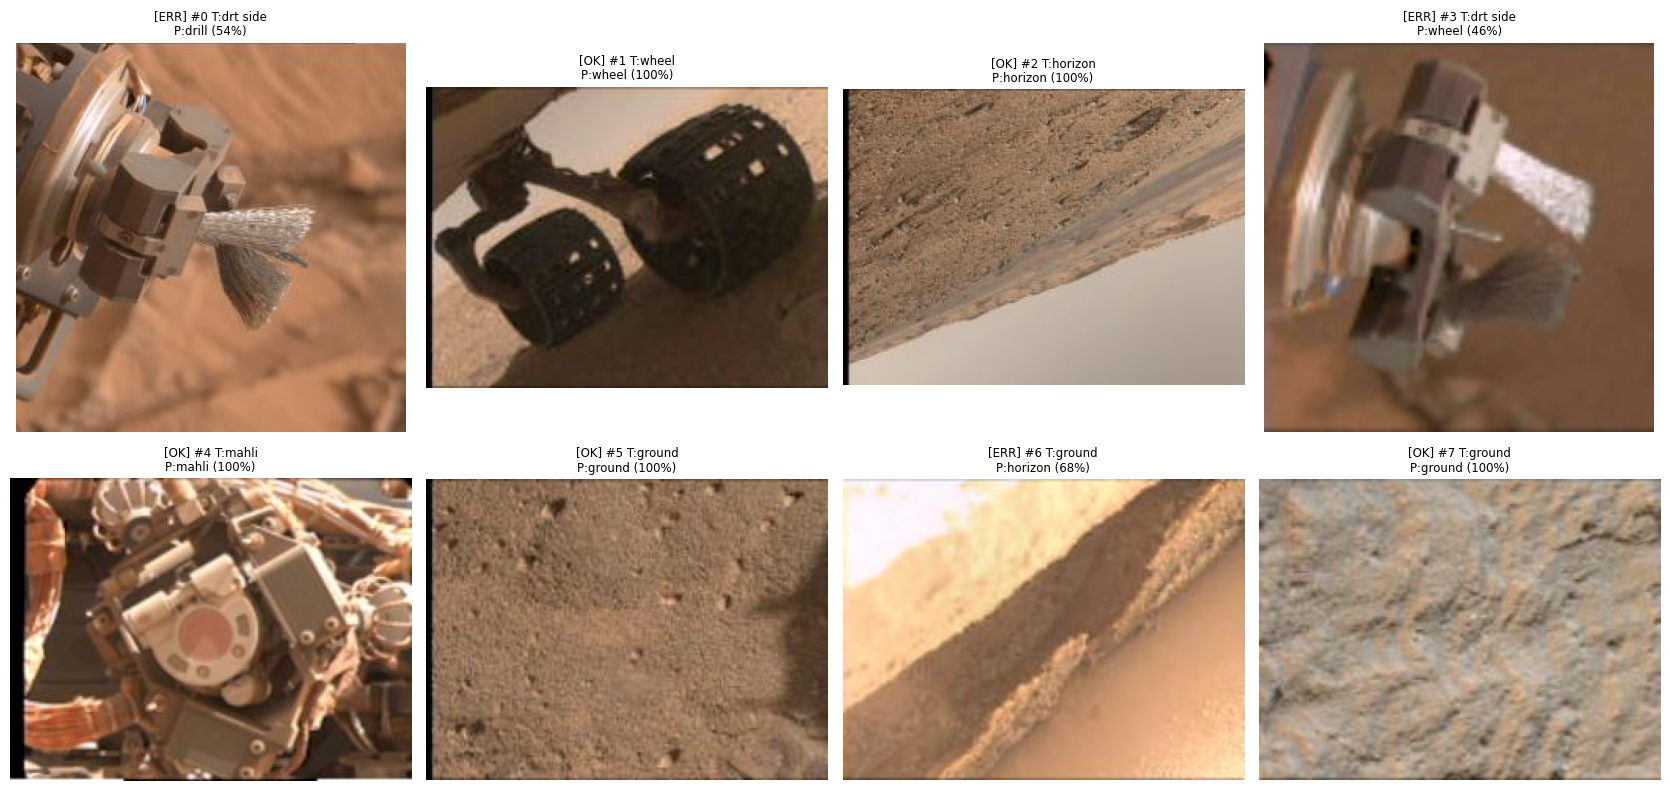

[ERR] #0 | True: drt side | Pred: drill (54.4%)
[ERR] #3 | True: drt side | Pred: wheel (46.4%)
[ERR] #6 | True: ground | Pred: horizon (68.0%)
[ERR] #14 | True: drt side | Pred: scoop (94.2%)
[ERR] #17 | True: ground | Pred: horizon (55.0%)
[ERR] #20 | True: ground | Pred: horizon (95.7%)
[ERR] #28 | True: ground | Pred: horizon (52.1%)
[ERR] #44 | True: wheel | Pred: ground (34.7%)


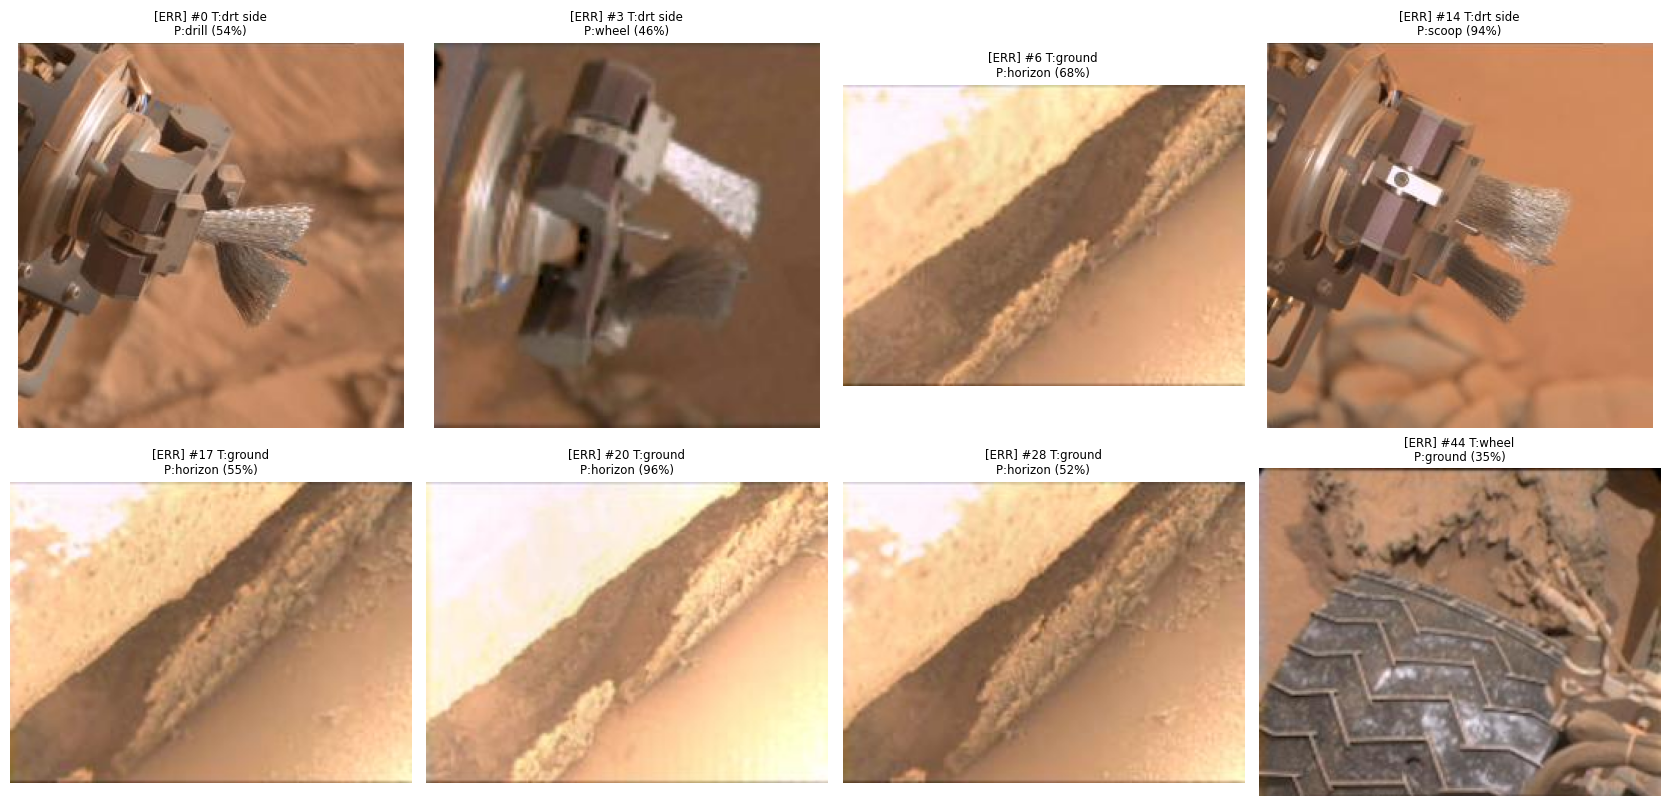

Created dataset file at: .gradio\flagged\dataset1.csv


In [ ]:
@torch.no_grad()
def inspect_test_predictions(ckpt_path: Path, samples: list, num_samples: int = 8, only_errors: bool = False):
    ckpt = torch.load(ckpt_path, map_location=device)
    classes = ckpt["label_names"]

    net = models.resnet18(weights=None)
    net.fc = nn.Linear(net.fc.in_features, ckpt["num_classes"])
    net.load_state_dict(ckpt["model_state_dict"])
    net.to(device)
    net.eval()

    selected = []
    for idx, (img_path, true_idx) in enumerate(samples):
        with Image.open(img_path) as im:
            rgb = im.convert("RGB").copy()
        tensor = eval_transform(rgb).unsqueeze(0).to(device)
        probs = torch.softmax(net(tensor), dim=1).squeeze(0).cpu().numpy()
        pred_idx = int(np.argmax(probs))
        conf = float(probs[pred_idx])
        is_err = pred_idx != true_idx
        if not only_errors or is_err:
            selected.append((idx, rgb, true_idx, pred_idx, conf, probs, classes))
        if len(selected) >= num_samples:
            break

    cols = min(4, max(len(selected), 1))
    rows = (len(selected) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4.2 * rows))
    axes = np.atleast_1d(axes).flatten()

    for ax, (idx, rgb, true_idx, pred_idx, conf, probs, cls_list) in zip(axes, selected):
        mark = "OK" if pred_idx == true_idx else "ERR"
        print(f"[{mark}] #{idx} | True: {cls_list[true_idx]} | Pred: {cls_list[pred_idx]} ({conf:.1%})")
        ax.imshow(rgb)
        ax.set_title(f"[{mark}] #{idx} T:{cls_list[true_idx]}\nP:{cls_list[pred_idx]} ({conf:.0%})", fontsize=8.5)
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# Inspect first 8 test samples, then inspect misclassified ones
inspect_test_predictions(checkpoint_path, test_items, num_samples=8, only_errors=False)
inspect_test_predictions(checkpoint_path, test_items, num_samples=8, only_errors=True)